# E-commerce Product Analytics — Purchase Retention

## 1. Business Questions

This analysis focuses on repeat purchase behavior and answers the following questions:

- Do users make a repeat purchase after their first purchase?
- How does repeat purchase behavior change across different time periods?
- How does purchase retention differ between purchase cohorts?
- Which retention definition provides the most useful view of repeat purchase behavior?
- What patterns require further investigation?

The analysis uses `checkout_complete` as the purchase event.

## 2. Purchase Retention Metrics

- **Purchase** — a `checkout_complete` event. Several purchases on the same calendar day count as one purchase day.
- **Purchase cohort** — group of users whose first purchase falls in the same calendar month.
- **Exact-Day Purchase Retention** — percentage of eligible users who make a repeat purchase exactly N days after their first purchase.
- **Bracket Purchase Retention** — percentage of eligible users who make at least one repeat purchase within a time interval after their first purchase (Day 1–7, 8–14, 15–30, 31+).
- **D30 Unbounded Purchase Retention** — percentage of eligible users who make at least one repeat purchase on Day 30 or later.

Definitions follow Amplitude's terminology for N-day, unbounded and bracket retention (see References), applied to purchases instead of any activity.

## 3. Data

The analysis uses `events_clean` (see `01_engagement.ipynb`, Section 4) for consistency with the other analyses. Purchases are `checkout_complete` events; 967 of 1,000 users make at least one purchase.

Main fields:

- `user_id` — identifies the user
- `event_time` — timestamp of the event
- `event_name` — type of event; `checkout_complete` is a completed purchase

**Cohort.** Each user's purchase cohort is the month of their first purchase.

**Observation window.** The last day in the data (18 August 2025) is only partly covered, so the data end is the start of that day — the same boundary as in the other notebooks. Day N of a user is included only if it is fully observed (first purchase date + N < 18 August 2025); otherwise the user is not eligible for that day, and the value is left empty rather than set to zero.

**Monthly values are calculated over users.** Retention for a cohort month is the share of all eligible users of that month, and the summary tables show both the average across cohorts and the average weighted by users.

The query results are in `data/results/03_purchase_retention/` and can be re-created with `python scripts/export_results.py`.

### Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.alpha': 0.3
})


def read_cohorts(folder, file_name):
    """Read a cohort table and keep the cohort month as a monthly period."""
    df = pd.read_csv(f"../data/results/{folder}/{file_name}")
    df["cohort_month"] = pd.to_datetime(df["cohort_month"]).dt.to_period("M")
    return df


def summarize(df, key):
    """Eligible and returned users, average by cohort and average weighted by user for each value of key."""
    totals = df.groupby(key)[["eligible_users", "returned_users"]].sum()
    pct = df.groupby(key)["retention_pct"]
    return pd.DataFrame({
        "Eligible users": totals["eligible_users"],
        "Returned users": totals["returned_users"],
        "Average (by cohort)": pct.mean(),
        "Weighted average (by user)": totals["returned_users"] * 100 / totals["eligible_users"],
        "Median": pct.median(),
        "Minimum": pct.min(),
        "Maximum": pct.max(),
    })

## 4. Data Quality Check: the Anomaly Does Not Affect Purchases

The anomalous June–August 2023 sessions found in `01_engagement.ipynb` consist of `website_visit`, `view_product_page`, `add_to_cart` and `session_end` — they contain no `checkout_complete` events. Purchases should therefore be identical in `events` and `events_clean`.

In [2]:
pd.read_csv("../data/results/03_purchase_retention/purchase_anomaly_check.csv")

,purchases_all_events,purchases_events_clean,purchasers,users
0,4517,4517,967,1000


**Result:** both tables contain 4,517 purchases, so purchase cohorts and purchase retention are not affected by the anomaly. Unlike activity-based cohorts in `02_retention_cohorts.ipynb`, no before/after comparison is needed here.

## 5. Exact-Day Purchase Retention

### Business Question

Do users make a repeat purchase exactly N days after their first purchase?

### Definition

**Exact-Day Purchase Retention** measures the percentage of eligible users who make a repeat purchase exactly N days after their first purchase.

The analysis uses Day 1, Day 2, Day 3, Day 7, Day 14, and Day 30.

Only users with enough observation time to reach the corresponding day are included.

### Methodological Note

Exact-Day Purchase Retention measures whether a user made a repeat purchase on one specific calendar day after the first purchase. This is a narrow definition: a user who makes a repeat purchase a few days earlier or later is not counted for that day, so Exact-Day Purchase Retention can be low even when users purchase repeatedly over a broader window.

Exact-Day Purchase Retention is not cumulative. A higher value on a later day does not indicate that retention improved over time.

### SQL

[01_exact_day.sql](../sql/03_purchase_retention/01_exact_day.sql)

### Results

In [3]:
exact = read_cohorts("03_purchase_retention", "purchase_exact_day_retention_monthly.csv")

display(pd.concat([exact.head(6), exact.tail(6)]))

,cohort_month,cohort_users,day_n,eligible_users,returned_users,retention_pct
0,2023-01,21,1,21,2,9.52
1,2023-01,21,2,21,0,0.00
2,2023-01,21,3,21,1,4.76
3,2023-01,21,7,21,2,9.52
4,2023-01,21,14,21,2,9.52
5,2023-01,21,30,21,3,14.29
180,2025-07,5,1,5,0,0.00
181,2025-07,5,2,5,0,0.00
182,2025-07,5,3,5,0,0.00
183,2025-07,5,7,5,0,0.00


### Cohort Sizes

Purchase cohorts contain 5–51 users (31.2 on average). The last two cohorts are small — 9 users in June 2025 and 5 in July 2025 — because purchases continue only until mid-August 2025.

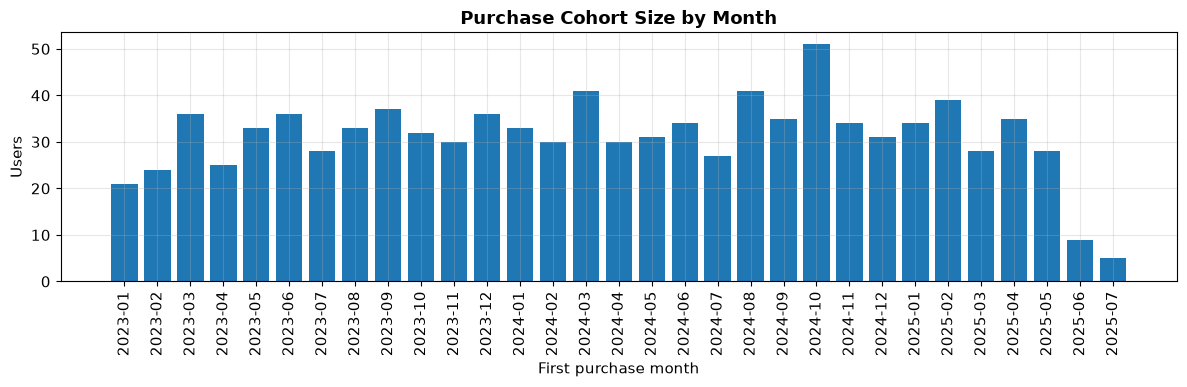

In [4]:
cohort_sizes = exact.groupby("cohort_month")["cohort_users"].first()

plt.figure(figsize=(12, 4))
plt.bar(cohort_sizes.index.astype(str), cohort_sizes.values, color="tab:blue")
plt.title("Purchase Cohort Size by Month")
plt.xlabel("First purchase month")
plt.ylabel("Users")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Summary

**Average (by cohort)** treats every cohort equally and describes a typical cohort. **Weighted average (by user)** divides the total number of users with a repeat purchase by the total number of eligible users and describes retention across all eligible users combined.

In [5]:
exact_summary = summarize(exact, "day_n").rename(index=lambda n: f"Day {n}")

display(exact_summary.round(2))

,Eligible users,Returned users,Average (by cohort),Weighted average (by user),Median,Minimum,Maximum
day_n,,,,,,,
Day 1,967,39,3.93,4.03,3.03,0.0,9.68
Day 2,967,40,4.03,4.14,3.70,0.0,17.14
Day 3,967,43,4.25,4.45,3.57,0.0,9.80
Day 7,967,42,4.48,4.34,4.00,0.0,12.12
Day 14,967,60,6.67,6.20,6.06,0.0,20.00
Day 30,966,56,5.51,5.80,3.70,0.0,16.67


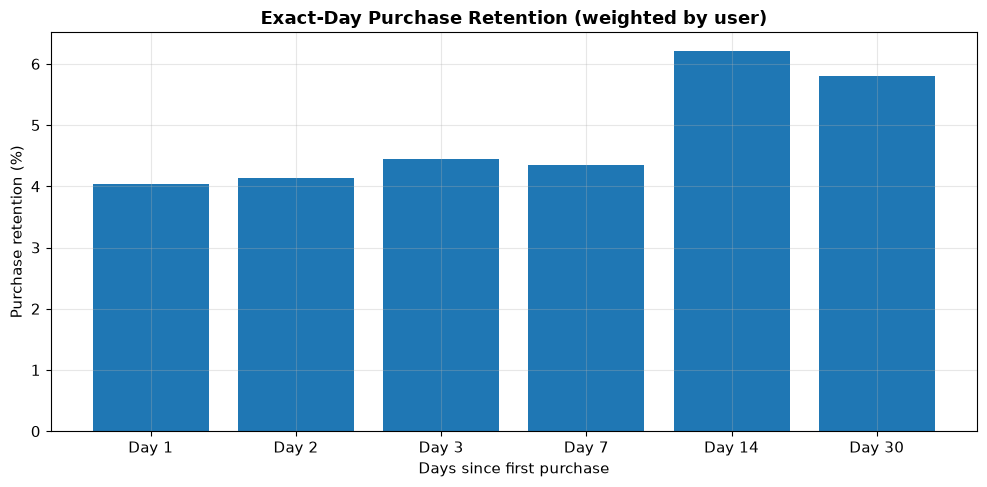

In [6]:
plt.figure(figsize=(10, 5))
plt.bar(exact_summary.index, exact_summary["Weighted average (by user)"], color="tab:blue")
plt.ylabel("Purchase retention (%)")
plt.xlabel("Days since first purchase")
plt.title("Exact-Day Purchase Retention (weighted by user)")
plt.tight_layout()
plt.show()

### Finding

Exact-Day Purchase Retention is low: 4.03% of eligible users make a repeat purchase exactly on Day 1, 4.34% on Day 7, 6.20% on Day 14 and 5.80% on Day 30 (weighted by user; the averages across cohorts are similar, 3.93–6.67%). Individual cohorts range from 0% to 20%.

There is no clear decline in the observed Exact-Day Purchase Retention from Day 1 to Day 30: the weighted retention rates remain within approximately 4–6% on the analysed days. These days cover the first month only; Section 8 shows how repeat purchases change after Day 30.

### Product Interpretation

A specific calendar day is a narrow window for a repeat purchase, so Exact-Day Purchase Retention mainly shows the share of eligible users who buy again on a given day — about 4–6%. Broader time intervals give a more useful view of repeat purchase behaviour.

## 6. Bracket Purchase Retention

### Business Question

Do users make at least one repeat purchase within defined time intervals after their first purchase?

### Definition

**Bracket Purchase Retention** measures whether a user made at least one repeat purchase during a defined time interval after their first purchase.

The brackets used in this analysis are:

- Day 1–7
- Day 8–14
- Day 15–30
- Day 31+

Important distinction:

- Exact-Day Purchase Retention asks whether the user purchased exactly on Day N.
- Unbounded Purchase Retention asks whether the user purchased on Day N or later.
- Bracket Purchase Retention asks whether the user purchased at least once within a specific time interval.

Only users with sufficient observation time are included in each bracket.

### SQL

[02_bracket.sql](../sql/03_purchase_retention/02_bracket.sql)

### Results

In [7]:
bracket = read_cohorts("03_purchase_retention", "purchase_bracket_retention_monthly.csv")

display(pd.concat([bracket.head(4), bracket.tail(4)]))

,cohort_month,cohort_users,bracket_order,bracket,eligible_users,returned_users,retention_pct
0,2023-01,21,1,Day 1-7,21,6,28.57
1,2023-01,21,2,Day 8-14,21,7,33.33
2,2023-01,21,3,Day 15-30,21,14,66.67
3,2023-01,21,4,Day 31+,21,20,95.24
120,2025-07,5,1,Day 1-7,5,0,0.00
121,2025-07,5,2,Day 8-14,5,2,40.00
122,2025-07,5,3,Day 15-30,4,1,25.00
123,2025-07,5,4,Day 31+,4,0,0.00


In [8]:
bracket_summary = summarize(bracket, ["bracket_order", "bracket"]).droplevel("bracket_order")

display(bracket_summary.round(2))

,Eligible users,Returned users,Average (by cohort),Weighted average (by user),Median,Minimum,Maximum
bracket,,,,,,,
Day 1-7,967,260,26.29,26.89,26.47,0.00,40.63
Day 8-14,967,281,29.17,29.06,29.27,11.11,52.00
Day 15-30,966,506,51.27,52.38,53.66,25.00,70.73
Day 31+,966,733,73.05,75.88,75.76,0.00,95.24


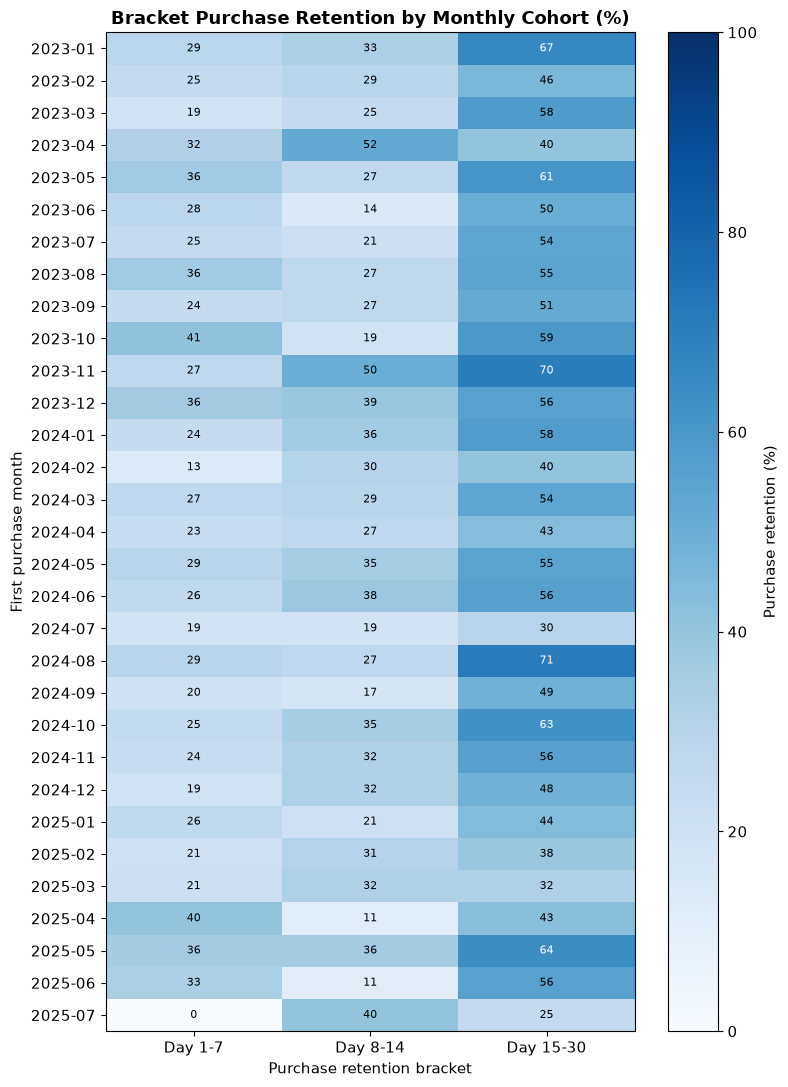

In [9]:
heatmap_data = bracket.pivot(index="cohort_month", columns="bracket", values="retention_pct")[["Day 1-7", "Day 8-14", "Day 15-30"]]

fig, ax = plt.subplots(figsize=(8, 11))
image = ax.imshow(heatmap_data, aspect="auto", interpolation="nearest", vmin=0, vmax=100, cmap="Blues")
fig.colorbar(image, label="Purchase retention (%)")

# value labels, so the table can be read without relying on colour alone
for row in range(heatmap_data.shape[0]):
    for col in range(heatmap_data.shape[1]):
        value = heatmap_data.iat[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if value > 60 else "black")

ax.set_xticks(range(heatmap_data.shape[1]))
ax.set_xticklabels(heatmap_data.columns)
ax.set_yticks(range(heatmap_data.shape[0]))
ax.set_yticklabels(heatmap_data.index.astype(str))
ax.set_xlabel("Purchase retention bracket")
ax.set_ylabel("First purchase month")
ax.set_title("Bracket Purchase Retention by Monthly Cohort (%)")
ax.grid(False)
plt.tight_layout()
plt.show()

### Finding

Weighted by user, 26.89% of eligible users make at least one repeat purchase on Day 1–7, 29.06% on Day 8–14, 52.38% on Day 15–30 and 75.88% on Day 31 or later (the averages across cohorts are similar: 26.29%, 29.17%, 51.27% and 73.05%).

The higher value for Day 15–30 does not mean that retention improves over time: this bracket is 16 days long, while the first two brackets are 7 days. During the first 30 days, the pattern is consistent with a roughly constant daily repeat-purchase rate of about 4.5% in this synthetic dataset, which would give about 28% for a 7-day window and about 52% for a 16-day window. The closed brackets do not show a clear decline within the first 30 days. However, the brackets have different lengths and may include different eligible users, so the rates should not be interpreted as a direct measure of how repeat-purchase behaviour changes over time.

Individual cohorts range from 0% to 41% for Day 1–7, 11% to 52% for Day 8–14 and 25% to 71% for Day 15–30. Cohorts contain about 31 users, so the value of a single cohort can change noticeably because of a few users, and differences between individual cohorts should be interpreted with caution.

These are separate time intervals, and a user can make no purchase in one bracket and purchase in a later one.

### Eligibility and Observation Time

A bracket is included only if it is fully observed, so recent cohorts are not eligible for later brackets. The open-ended Day 31+ bracket has another limitation: the time after Day 31 that can be observed differs between cohorts. The data for a 2023 cohort cover up to two years, while the July 2025 cohort has only a few weeks left before the data ends, so Day 31+ values of recent cohorts are lower and not comparable with older cohorts. Even for older cohorts, Day 31+ does not show long-term repeat purchasing: a user's activity is observed only for about three months after their first event (`02_retention_cohorts.ipynb`, Section 6), and a median of 76 days after the first purchase (Section 8).

## 7. Unbounded Purchase Retention

### Business Question

Do users make at least one repeat purchase on Day 30 or later after their first purchase?

### Definition

**D30 Unbounded Purchase Retention** measures the percentage of eligible users who make at least one repeat purchase on Day 30 or later after their first purchase.

Important distinction:

- Exact-Day Purchase Retention asks whether the user purchased exactly on Day 30.
- Unbounded Purchase Retention asks whether the user made at least one repeat purchase on Day 30 or any day after.

Only users with at least 30 days of observable time are included.

### SQL

[03_unbounded.sql](../sql/03_purchase_retention/03_unbounded.sql)

### Results

In [10]:
unbounded = read_cohorts("03_purchase_retention", "purchase_unbounded_retention_monthly.csv")
unbounded = unbounded.rename(columns={"d30_unbounded_purchase_retention": "retention_pct"})

display(pd.concat([unbounded.head(3), unbounded.tail(5)]))

,cohort_month,eligible_users,returned_users,retention_pct
0,2023-01,21,20,95.24
1,2023-02,24,19,79.17
2,2023-03,36,28,77.78
26,2025-03,28,18,64.29
27,2025-04,35,26,74.29
28,2025-05,28,20,71.43
29,2025-06,9,3,33.33
30,2025-07,4,0,0.00


In [11]:
unbounded_summary = summarize(unbounded.assign(metric="D30 Unbounded"), "metric")

display(unbounded_summary.round(2))

,Eligible users,Returned users,Average (by cohort),Weighted average (by user),Median,Minimum,Maximum
metric,,,,,,,
D30 Unbounded,966,738,73.44,76.4,76.67,0.0,95.24


### Finding

Weighted by user, 76.4% of eligible users make at least one repeat purchase on Day 30 or later (73.44% on average across cohorts, median 76.67%). From January 2023 to May 2025 the cohorts range from 64% to 95%. The June and July 2025 cohorts are much lower (33% and 0%), but they contain only 9 and 4 eligible users and can be observed for only a few weeks after Day 30.

### Data Limitation

D30 Unbounded Purchase Retention depends on how long a cohort can be observed after Day 30: the data for older cohorts cover up to two years, for recent cohorts only weeks. The metric is therefore not comparable between old and recent cohorts, and the low values of the last two cohorts reflect the end of the data rather than lower purchase retention. In all cohorts, a user's activity is observed only for a limited time after the first purchase (Section 8), so a high D30 Unbounded value does not show repeat purchasing over a long period.

## 8. Repeat Purchases Beyond Day 30

### Business Question

How do repeat purchases change after Day 30?

### SQL

[04_long_horizon.sql](../sql/03_purchase_retention/04_long_horizon.sql)

Sections 5–7 cover Days 1–30 and the open-ended Day 31+ and D30 Unbounded metrics. Activity-based retention stops after about three months (`02_retention_cohorts.ipynb`, Section 6), so open-ended metrics cannot show what happens to repeat purchases later. The queries below look at all purchasers together, without splitting by cohort:

1. Exact-Day Purchase Retention on Days 1–100;
2. closed, non-overlapping 30-day intervals up to Day 120;
3. how many days of observed activity a user has left after the first purchase.

A user is eligible for a day or an interval only if it is fully observed; the number of eligible users is shown for each of them. Because eligible users differ slightly between days and intervals, the values are also shown for a fixed group: the 911 purchasers whose whole 120-day horizon after the first purchase is observed.

### Results

In [12]:
purchase_long = pd.read_csv("../data/results/03_purchase_retention/purchase_retention_long_horizon.csv")

purchase_long

,day_n,eligible_users,returned_users,retention_pct,full_horizon_users,full_horizon_retention_pct
0,1,967,39,4.03,911,3.95
1,7,967,42,4.34,911,4.28
2,14,967,60,6.20,911,6.26
3,30,966,56,5.80,911,6.04
4,45,964,58,6.02,911,5.93
5,60,959,44,4.59,911,4.61
6,70,958,31,3.24,911,3.40
7,80,951,21,2.21,911,2.20
8,90,941,4,0.43,911,0.44
9,100,933,0,0.00,911,0.00


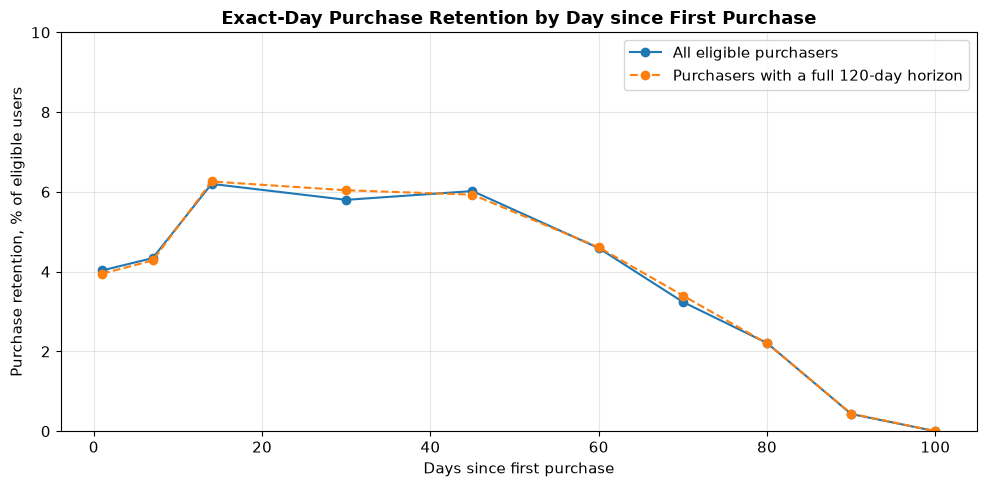

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(purchase_long["day_n"], purchase_long["retention_pct"], marker="o", color="tab:blue",
         label="All eligible purchasers")
plt.plot(purchase_long["day_n"], purchase_long["full_horizon_retention_pct"], marker="o", linestyle="--", color="tab:orange",
         label="Purchasers with a full 120-day horizon")

plt.title("Exact-Day Purchase Retention by Day since First Purchase")
plt.xlabel("Days since first purchase")
plt.ylabel("Purchase retention, % of eligible users")
plt.ylim(0, 10)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
pd.read_csv("../data/results/03_purchase_retention/purchase_retention_intervals.csv")

,interval_name,eligible_users,returned_users,retention_pct,full_horizon_users,full_horizon_retention_pct
0,Day 1-30,966,681,70.50,911,70.58
1,Day 31-60,959,654,68.20,911,68.94
2,Day 61-90,941,422,44.85,911,44.79
3,Day 91-120,911,0,0.00,911,0.00


In [15]:
pd.read_csv("../data/results/03_purchase_retention/purchase_activity_after_first_purchase.csv")

,full_horizon_users,min_days_left,p25_days_left,median_days_left,p75_days_left,max_days_left,pct_less_than_31_days,pct_less_than_61_days,pct_less_than_91_days
0,911,0,62,76.0,84,91,5.9,23.1,99.2


### Finding

Exact-Day Purchase Retention stays at about 4–6% from Day 1 to Day 45 (4.03–6.20%) and then declines: 4.59% on Day 60, 3.24% on Day 70, 2.21% on Day 80, 0.43% on Day 90 and 0% on Day 100, while 933 users are still eligible on Day 100. In closed 30-day intervals, 70.5% of eligible users make at least one repeat purchase in Day 1–30, 68.2% in Day 31–60, 44.85% in Day 61–90 and 0% in Day 91–120. The fixed group of 911 purchasers shows the same values (70.58%, 68.94%, 44.79% and 0%), so the decline is not caused by a change in which users are eligible.

The decline coincides with the end of users' observed activity. After the first purchase, a user has a median of 76 days of observed activity left (interquartile range 62–84 days, at most 91). 23.1% of these purchasers have no observed activity after Day 60, and 99.2% none after Day 90. So the drop in Day 61–90 and the absence of repeat purchases after Day 90 are consistent with users' activity ending, not necessarily with a change in how often active users buy.

The roughly constant repeat-purchase rate described in Sections 5 and 6 therefore holds for about the first one and a half months after the first purchase. Day 31+ and D30 Unbounded Purchase Retention combine these periods and should not be read as evidence of stable repeat purchasing over a long period.

## 9. Product Retention vs Purchase Retention

### Business Question

How does activity-based retention compare with purchase retention, and what does the difference tell us about user behaviour?

### Methodological Note

The two metrics use different cohort anchors:

- **Product Retention** (`02_retention_cohorts.ipynb`) — users are grouped by the month of their first event and count as retained if they have any event on Day N.
- **Purchase Retention** — users are grouped by the month of their first purchase and count as retained if they make a repeat purchase on Day N.

Both use cleaned data, monthly cohorts and the same observation window. The comparison therefore describes two different stages of the customer journey rather than two versions of the same metric. Day 7 is used because it is available for both analyses.

In [16]:
product = read_cohorts("02_retention_cohorts", "exact_day_retention_monthly.csv")

comparison = pd.concat([
    product[product["day_n"] == 7].set_index("cohort_month")["retention_pct"].rename("Product Retention, Day 7"),
    exact[exact["day_n"] == 7].set_index("cohort_month")["retention_pct"].rename("Purchase Retention, Day 7"),
], axis=1)

display(comparison.round(2))

,"Product Retention, Day 7","Purchase Retention, Day 7"
cohort_month,,
2023-01,52.63,9.52
2023-02,37.50,4.17
2023-03,54.55,5.56
2023-04,53.85,4.00
2023-05,66.67,6.06
2023-06,50.00,5.56
2023-07,41.38,3.57
2023-08,51.16,12.12
2023-09,57.14,2.70


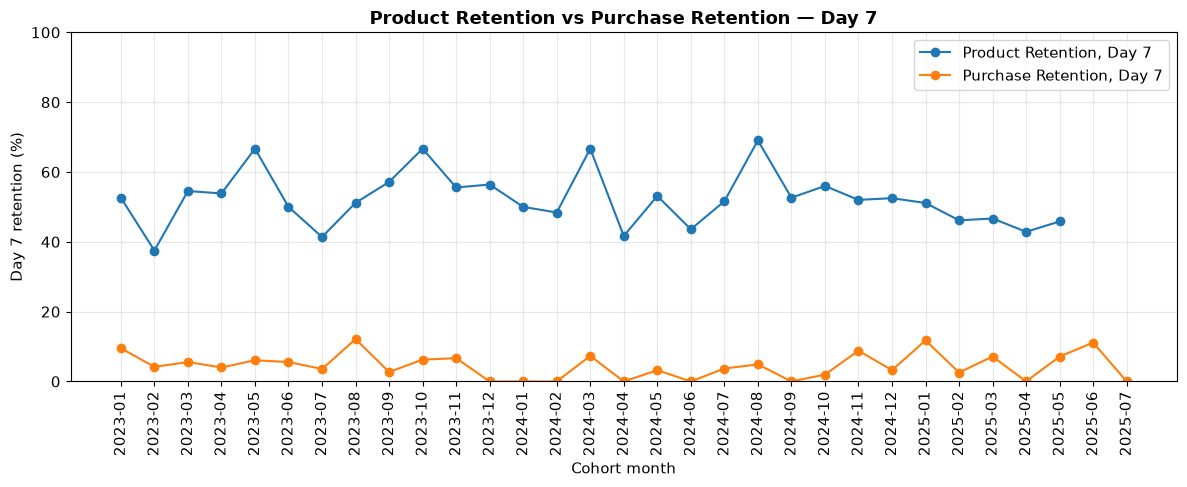

In [17]:
plt.figure(figsize=(12, 5))
plt.plot(comparison.index.astype(str), comparison["Product Retention, Day 7"], marker="o", label="Product Retention, Day 7")
plt.plot(comparison.index.astype(str), comparison["Purchase Retention, Day 7"], marker="o", label="Purchase Retention, Day 7")
plt.xlabel("Cohort month")
plt.ylabel("Day 7 retention (%)")
plt.ylim(0, 100)
plt.title("Product Retention vs Purchase Retention — Day 7")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

### Finding

On Day 7, about half of users are active in the product (52.5% weighted by user), but only about 4% of eligible users make a repeat purchase on that day (4.34%). The gap is stable across cohorts: Product Retention stays at 38–69% and Purchase Retention at 0–12%.

Returning to the product and making a repeat purchase are different behaviours. The gap between the two metrics suggests that further analysis of the relationship between product activity and repeat purchasing would be useful. Because the metrics use different cohort anchors and denominators, this comparison does not establish how many active users make a purchase.

### Product Interpretation

Product Retention and Purchase Retention are complementary. Product Retention describes whether users keep interacting with the product; Purchase Retention describes whether customers buy again. Before explaining the gap, both metrics would need to be compared for the same users and over the same observation period; here they use different cohorts and denominators. For an e-commerce product, the gap between the two is a starting point for investigating where returning users drop off before a repeat purchase — for example, in the checkout funnel (`04_funnel.ipynb`).

## 10. Key Findings

- **The anomaly does not affect purchases.** The anomalous June–August 2023 sessions contain no purchases: `events` and `events_clean` both have 4,517 `checkout_complete` events.
- **Repeat purchases on a specific day are rare.** Weighted by user, Exact-Day Purchase Retention is 4.03% on Day 1, 4.34% on Day 7, 6.20% on Day 14 and 5.80% on Day 30.
- **Over wider windows, repeat purchases become common.** Bracket Purchase Retention is 26.89% for Day 1–7, 29.06% for Day 8–14 and 52.38% for Day 15–30; 76.4% of eligible users with at least 30 days of observable time make a repeat purchase on Day 30 or later.
- **No clear decline in the first month; observed repeat purchases decline as observed activity ends.** During the first 30 days, the bracket values are consistent with a roughly constant daily repeat-purchase rate of about 4.5%. Exact-Day Purchase Retention stays at about 4–6% until Day 45, then falls to 0.43% on Day 90 and 0% on Day 100; in closed intervals, 70.5% of eligible users make a repeat purchase in Day 1–30, 68.2% in Day 31–60, 44.85% in Day 61–90 and 0% in Day 91–120. The decline coincides with the end of users' observed activity (a median of 76 days after the first purchase), so it is not interpreted as a change in purchasing behaviour.
- **Returning and buying are different behaviours.** On Day 7, 52.5% of users are active in the product and 4.34% of eligible users make a repeat purchase. The metrics use different cohorts and denominators, so the comparison does not show how many active users buy.

## 11. Product Interpretation

The definition of purchase retention strongly affects its level. Depending on the retention definition and observation window, the observed retention ranges from about 4% on a specific day to about 27% within the first week and about 76% on Day 30 or later. For monitoring repeat purchases in an e-commerce product, closed-window bracket retention is particularly informative: it captures purchasing within a defined interval while requiring a consistent observation window. Exact-day retention is narrower, while open-ended metrics such as Day 31+ and D30 Unbounded remain sensitive to the length of follow-up.

As with activity-based retention, repeat purchasing shows no clear decline during the first month, and cohorts behave similarly; afterwards, repeat purchases fade out as users' observed activity ends, and none are observed after Day 90. A constant rate followed by a stop is unusual for a real product and likely reflects how the synthetic data was generated. Further analysis should focus on the gap between returning and buying (funnel analysis), purchase frequency and segmentation by acquisition channel.

## 12. Next Questions

1. At which funnel step do returning users drop off before a repeat purchase (`04_funnel.ipynb`)?
2. Does repeat purchase behaviour differ by acquisition channel or country?
3. How many purchases does a typical purchaser make, and how is the time between purchases distributed?
4. How does repeat purchase behaviour relate to revenue and LTV (`06_acquisition_monetization.ipynb`)?
5. Among users who are still active, does the daily probability of a repeat purchase stay constant after Day 30?

## 13. Limitations

- The dataset is synthetic: the daily repeat-purchase rate is roughly constant during the first month, and a user's activity is observed only for a limited time after the first purchase (no repeat purchases after Day 90), so the data do not show long-term repeat-purchase behaviour.
- Purchases are `checkout_complete` events; order value is not available, so the analysis covers repeat purchase timing, not revenue.
- Purchase cohorts are small (5–51 users, about 31 on average), so the value of a single cohort can change noticeably because of a few users.
- Open-ended metrics (Day 31+ bracket and D30 Unbounded) depend on how long a cohort can be observed, so they are not comparable between old and recent cohorts.
- 12 purchases are recorded before the user's sign-up date; they are kept, as the effect on the results is negligible.
- The analysis is observational and does not establish causal relationships.

## 14. References

Retention and cohort definitions follow Amplitude's product analytics materials:

- Amplitude — [Retention Analytics: Retention Analytics For Stopping Churn In Its Tracks](https://amplitude.com/guides/retention-analytics) (N-day, unbounded and bracket retention)
- Amplitude — [The Complete Guide to Cohort Analysis](https://amplitude.com/explore/analytics/cohort-analysis)
- Dataset — [adisomani/duckdb_product_analytics_tutorial](https://github.com/adisomani/duckdb_product_analytics_tutorial)